# Efficient Data Handling through Data Parallelism

**Bank marketing dataset (bank.csv) with Apache Spark** · Part 5 of the distributed ML project · Taha Saifee

GitHub: https://github.com/Tahascommit/bank-distributed-ml

This notebook answers the Part 5 questions: how to split the data into partitions, how to run the analysis and the
model training in parallel over those partitions, how the CPU and memory are used while that happens, and how to run
several preprocessing tasks at the same time. I ran it on my laptop (12 cores) with Spark in local mode, where every
core works as a parallel worker. The same code runs unchanged on a cluster, where the partitions would be spread over
several machines.

## 0. Setup

In [1]:
# setup: works on my mac and on google colab
import os, sys, json, time, threading, warnings, urllib.request
warnings.filterwarnings("ignore")

if "google.colab" in sys.modules:
    import subprocess
    subprocess.run("pip install -q pyspark==3.5.9", shell=True)
    if subprocess.run("java -version", shell=True, capture_output=True).returncode != 0:
        subprocess.run("apt-get install -y -qq openjdk-17-jdk-headless > /dev/null", shell=True)
        os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

# java 17 from homebrew on my mac
JAVA17 = "/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home"
if "JAVA_HOME" not in os.environ and os.path.isdir(JAVA17):
    os.environ["JAVA_HOME"] = JAVA17
# spark's python workers must use this same python
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

DATA = "../data/bank.csv"
if not os.path.exists(DATA):
    DATA = "bank.csv"
    urllib.request.urlretrieve("https://raw.githubusercontent.com/Tahascommit/bank-distributed-ml/main/data/bank.csv", DATA)
print("data:", DATA)

data: ../data/bank.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
from concurrent.futures import ThreadPoolExecutor
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.functions import spark_partition_id
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)

In [3]:
# spark's java process prints its startup warnings on stderr; they go to spark_driver.log instead of the notebook
log_fd = os.open("spark_driver.log", os.O_WRONLY | os.O_CREAT | os.O_TRUNC)
saved_stderr = os.dup(2)
os.dup2(log_fd, 2)
spark = (SparkSession.builder
         .master("local[*]")                                  # one worker thread per core
         .appName("part5-data-parallelism")
         .config("spark.ui.port", "4060")
         .config("spark.scheduler.mode", "FAIR")              # used in section 5
         .config("spark.sql.adaptive.enabled", "false")       # keep exactly the partition numbers I set
         .config("spark.sql.shuffle.partitions", str(os.cpu_count()))
         .config("spark.driver.memory", "4g")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
os.dup2(saved_stderr, 2); os.close(saved_stderr); os.close(log_fd)
spark.sparkContext.setLogLevel("ERROR")
sc = spark.sparkContext
CORES = sc.defaultParallelism
print(f"Spark {spark.version} | master {sc.master} | {CORES} cores = {CORES} tasks can run at the same time")
print(f"Spark UI: {sc.uiWebUrl}")

Spark 3.5.9 | master local[*] | 12 cores = 12 tasks can run at the same time
Spark UI: http://192.168.1.4:4060


## 1. Data Preparation and Partitioning

### 1.1 Load bank.csv into a Spark DataFrame and inspect the first rows

In [4]:
df = spark.read.csv(DATA, header=True, inferSchema=True)
df.show(5)
df.printSchema()
print(f"rows: {df.count()} | columns: {len(df.columns)} | partitions after reading: {df.rdd.getNumPartitions()}")

+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|        job|marital|education|default|balance|housing|loan| contact|day|month|duration|campaign|pdays|previous|poutcome|  y|
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
| 30| unemployed|married|  primary|     no|   1787|     no|  no|cellular| 19|  oct|      79|       1|   -1|       0| unknown| no|
| 33|   services|married|secondary|     no|   4789|    yes| yes|cellular| 11|  may|     220|       1|  339|       4| failure| no|
| 35| management| single| tertiary|     no|   1350|    yes|  no|cellular| 16|  apr|     185|       1|  330|       1| failure| no|
| 30| management|married| tertiary|     no|   1476|    yes| yes| unknown|  3|  jun|     199|       4|   -1|       0| unknown| no|
| 59|blue-collar|married|secondary|     no|      0|    yes|  no| unknown|  5|  may|     22

**Answer:** bank.csv has 4,521 rows and 17 columns. Spark read the whole file into **1 partition**, because it is only 375 KB and Spark only splits a file into several partitions when it is bigger than 128 MB. With one partition only 1 of my 12 cores would do any work, so the data has to be split before anything can run in parallel.

### 1.2 Dividing the dataset into partitions

I compared four ways of splitting the data into partitions. `spark_partition_id()` tells which partition each row
ended up in, so I can count the rows per partition for each strategy.

In [5]:
def rows_per_partition(d):
    """number of rows in every partition (empty partitions included)"""
    counts = (d.withColumn("partition", spark_partition_id())
               .groupBy("partition").count().toPandas().set_index("partition")["count"])
    return counts.reindex(range(d.rdd.getNumPartitions()), fill_value=0)

N = CORES
strategies = {
    "as read from the csv": df,
    f"round robin, repartition({N})": df.repartition(N),
    f"hash on job, repartition({N}, 'job')": df.repartition(N, "job"),
    f"range on balance, repartitionByRange({N}, 'balance')": df.repartitionByRange(N, "balance"),
}
sizes = {name: rows_per_partition(d) for name, d in strategies.items()}

pd.DataFrame([{"strategy": name, "partitions": len(s), "empty partitions": int((s == 0).sum()),
               "smallest": int(s.min()), "largest": int(s.max()),
               "largest / average": round(s.max() / s.mean(), 2)} for name, s in sizes.items()])

,strategy,partitions,empty partitions,smallest,largest,largest / average
0,as read from the csv,1,0,4521,4521,1.00
1,"round robin, repartition(12)",12,0,376,377,1.00
2,"hash on job, repartition(12, 'job')",12,5,0,1424,3.78
3,"range on balance, repartitionByRange(12, 'bala...",12,0,60,723,1.92


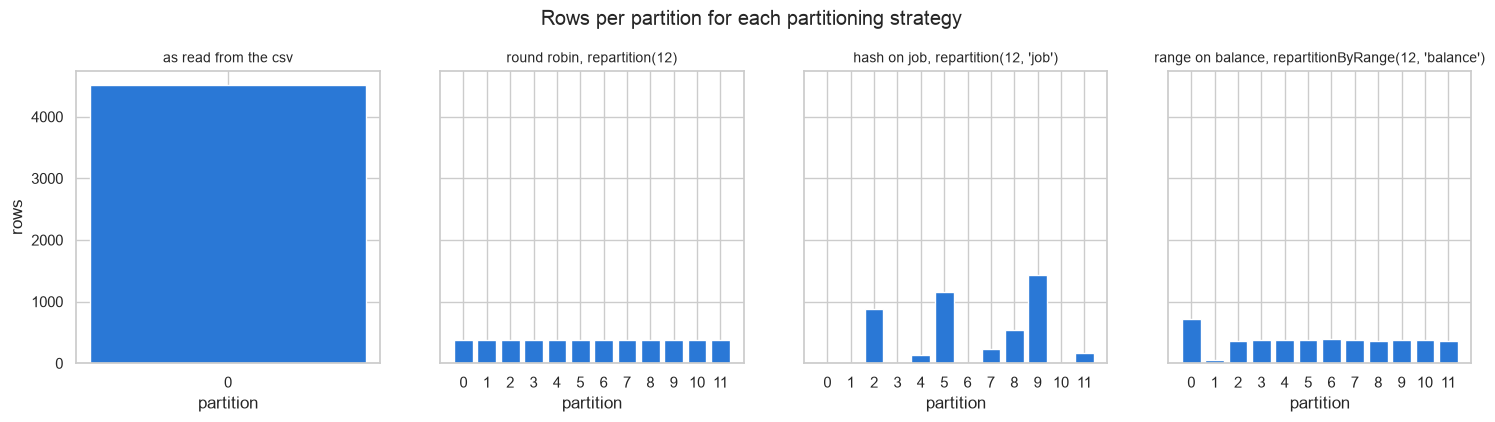

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, (name, s) in zip(axes, sizes.items()):
    ax.bar(s.index.astype(str), s.values, color="#2a78d6")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("partition")
axes[0].set_ylabel("rows")
plt.suptitle("Rows per partition for each partitioning strategy", y=1.04)
plt.show()

In [7]:
# which jobs land in which partition when I partition by job
(df.repartition(N, "job").withColumn("partition", spark_partition_id())
   .groupBy("partition").agg(F.count("*").alias("rows"), F.array_sort(F.collect_set("job")).alias("jobs"))
   .orderBy("partition").show(truncate=False))

+---------+----+----------------------------+
|partition|rows|jobs                        |
+---------+----+----------------------------+
|2        |880 |[housemaid, technician]     |
|4        |128 |[unemployed]                |
|5        |1152|[management, self-employed] |
|7        |230 |[retired]                   |
|8        |539 |[services, student, unknown]|
|9        |1424|[admin., blue-collar]       |
|11       |168 |[entrepreneur]              |
+---------+----+----------------------------+



Partitioning by key pays off later: when the data is already hash partitioned on `job`, a `groupBy("job")` doesn't
need another shuffle. Both plans below compute the same thing. The first one has a single `Exchange` (the
repartition I asked for), the second one adds an `Exchange hashpartitioning(job)` for the groupBy.

In [8]:
by_job = df.repartition(N, "job").cache()
by_job.count()   # materialize the cache
print("== already partitioned by job ==")
by_job.groupBy("job").agg(F.avg("balance")).explain()
print("== round robin partitions ==")
df.repartition(N).groupBy("job").agg(F.avg("balance")).explain()

== already partitioned by job ==
== Physical Plan ==
*(1) HashAggregate(keys=[job#18], functions=[avg(balance#22)])
+- *(1) HashAggregate(keys=[job#18], functions=[partial_avg(balance#22)])
   +- InMemoryTableScan [job#18, balance#22]
         +- InMemoryRelation [age#17, job#18, marital#19, education#20, default#21, balance#22, housing#23, loan#24, contact#25, day#26, month#27, duration#28, campaign#29, pdays#30, previous#31, poutcome#32, y#33], StorageLevel(disk, memory, deserialized, 1 replicas)
               +- Exchange hashpartitioning(job#18, 12), REPARTITION_BY_NUM, [plan_id=280]
                  +- FileScan csv [age#17,job#18,marital#19,education#20,default#21,balance#22,housing#23,loan#24,contact#25,day#26,month#27,duration#28,campaign#29,pdays#30,previous#31,poutcome#32,y#33] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/Users/taha/Desktop/Distributed ML/bank-distributed-ml/data/bank...., PartitionFilters: [], PushedFilters: [], Re

**Answer:** what the four strategies do with the data:

- **Round robin** (`repartition(12)`) deals the rows out like cards. Every partition gets 376 or 377 rows, perfectly even. A good default when the next step doesn't care which rows are together, for example model training.
- **Hash on job** (`repartition(12, 'job')`) puts all the rows of a job in the same partition. The sizes are very uneven: 5 of the 12 partitions are empty and the biggest one has 1,424 rows (admin. and blue-collar landed in the same bucket), 3.8 times the average. There are only 12 job values and some of them share a hash bucket. This is called data skew: the biggest partition decides how long the whole step takes.
- **Range on balance** (`repartitionByRange`) puts the rows into balance ranges (60 to 723 rows per partition). Useful for sorted output or queries on a balance range.

**The strategy I used:** round robin with as many partitions as cores (12) for general work and for the model training, because it spreads the work evenly over all the cores. For aggregations by job I used hash partitioning on job. The two plans above show why: when the data is already partitioned by job, the groupBy needs no second shuffle (one `Exchange` instead of two), because all the rows of a job are already together. With much bigger data I would use 2 to 4 partitions per core and aim for partitions of about 100 to 200 MB. This data is tiny, so 12 is enough.

## 2. Data Analysis and Processing in Parallel

### 2.1 Average balance per job, computed in parallel

**Way 1, DataFrame API.** Spark does the parallel work itself: each partition computes a partial sum and count per job
(`HashAggregate ... partial_avg` in the plans above), the partial results are shuffled so each job ends up in one
place, and a final aggregation combines them.

In [9]:
avg_df = (by_job.groupBy("job")
          .agg(F.count("*").alias("clients"), F.round(F.avg("balance"), 2).alias("avg_balance"))
          .orderBy(F.desc("avg_balance")))
avg_df.show()

+-------------+-------+-----------+
|          job|clients|avg_balance|
+-------------+-------+-----------+
|      retired|    230|    2319.19|
|    housemaid|    112|     2083.8|
|   management|    969|    1766.93|
| entrepreneur|    168|    1645.13|
|      student|     84|    1543.82|
|      unknown|     38|    1501.71|
|self-employed|    183|    1392.41|
|   technician|    768|     1331.0|
|       admin.|    478|    1226.74|
|     services|    417|    1103.96|
|   unemployed|    128|    1089.42|
|  blue-collar|    946|    1085.16|
+-------------+-------+-----------+



**Way 2, by hand with the RDD API**, to see the steps of data parallelism directly:
1. **map:** `mapPartitions` runs my function on every partition at the same time, and each one returns only
   `(job, (sum, count))` for its own rows.
2. **combine / reduce:** `reduceByKey` adds up the partial results of all partitions per job.
3. **finish:** divide sum by count.

In [10]:
def partial_sums(rows):
    """runs inside one partition: sum and count of the balance per job, for this partition only"""
    acc = {}
    for r in rows:
        s, c = acc.get(r.job, (0, 0))
        acc[r.job] = (s + r.balance, c + 1)
    return iter(acc.items())

rdd = df.select("job", "balance").repartition(N).rdd

# what the first two partitions computed on their own
partials = rdd.mapPartitionsWithIndex(lambda i, rows: ((i, job, s, c) for job, (s, c) in partial_sums(rows)))
print("partial results of partitions 0 and 1:")
print(pd.DataFrame(partials.collect(), columns=["partition", "job", "sum_balance", "rows"]).query("partition < 2").to_string(index=False))

by_hand = dict(rdd.mapPartitions(partial_sums)
                  .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
                  .mapValues(lambda t: round(t[0] / t[1], 2))
                  .collect())
check = avg_df.toPandas().assign(by_hand=lambda t: t.job.map(by_hand))
# compare to the cent: entrepreneur's average is exactly 1645.125, Spark rounds it to .13 and Python to .12
check["same"] = (check.avg_balance - check.by_hand).abs().round(2) <= 0.01
check

partial results of partitions 0 and 1:


 partition           job  sum_balance  rows
         0 self-employed        20752    20
         0    technician        95120    59
         0    management       197000    82
         0   blue-collar        98037    77
         0       retired        80232    26
         0      services        26250    34
         0        admin.        51468    45
         0  entrepreneur        23185    15
         0       student        13862     8
         0    unemployed         6002     5
         0     housemaid         1687     6
         1    technician        82944    58
         1    unemployed        20325    13
         1     housemaid        13517     8
         1   blue-collar        94495    75
         1    management       163653    85
         1      services        24689    41
         1 self-employed        30930    18
         1  entrepreneur        11600    12
         1       retired        32437    21
         1        admin.        61515    39
         1       unknown        

,job,clients,avg_balance,by_hand,same
0,retired,230,2319.19,2319.19,True
1,housemaid,112,2083.80,2083.80,True
2,management,969,1766.93,1766.93,True
3,entrepreneur,168,1645.13,1645.12,True
4,student,84,1543.82,1543.82,True
5,unknown,38,1501.71,1501.71,True
6,self-employed,183,1392.41,1392.41,True
7,technician,768,1331.00,1331.00,True
8,admin.,478,1226.74,1226.74,True
9,services,417,1103.96,1103.96,True


**Does it actually get faster with more partitions?** The real file is tiny (4,521 rows, 375 KB), so to measure the
effect of parallelism I made a bigger copy of the data: every row repeated 1,000 times (4,521,000 rows). Then I timed the
same work with 1, 2, 4, 8 and 12 partitions. Each setting runs 3 times and I keep the median.

In [11]:
SCALE = 1000
big = df.crossJoin(spark.range(SCALE).withColumnRenamed("id", "copy")).drop("copy")

def timed(fn, repeats=3):
    runs = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); runs.append(time.perf_counter() - t0)
    return float(np.median(runs))

speed = []
for parts in [1, 2, 4, 8, N]:
    d = big.repartition(parts).cache(); d.count()
    t_df = timed(lambda: d.groupBy("job").agg(F.avg("balance"), F.stddev("balance"),
                                              F.expr("percentile_approx(balance, 0.5)")).collect())
    t_rdd = timed(lambda: d.select("job", "balance").rdd.mapPartitions(partial_sums)
                           .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1])).collect())
    speed.append({"partitions": parts, "dataframe_sec": round(t_df, 2), "rdd_python_sec": round(t_rdd, 2)})
    d.unpersist()
speed = pd.DataFrame(speed)
speed["dataframe_speedup"] = (speed.dataframe_sec.iloc[0] / speed.dataframe_sec).round(1)
speed["rdd_python_speedup"] = (speed.rdd_python_sec.iloc[0] / speed.rdd_python_sec).round(1)
print(f"{big.count():,} rows")
speed

4,521,000 rows


,partitions,dataframe_sec,rdd_python_sec,dataframe_speedup,rdd_python_speedup
0,1,0.47,4.14,1.0,1.0
1,2,0.33,2.34,1.4,1.8
2,4,0.22,1.47,2.1,2.8
3,8,0.21,1.09,2.2,3.8
4,12,0.23,1.04,2.0,4.0


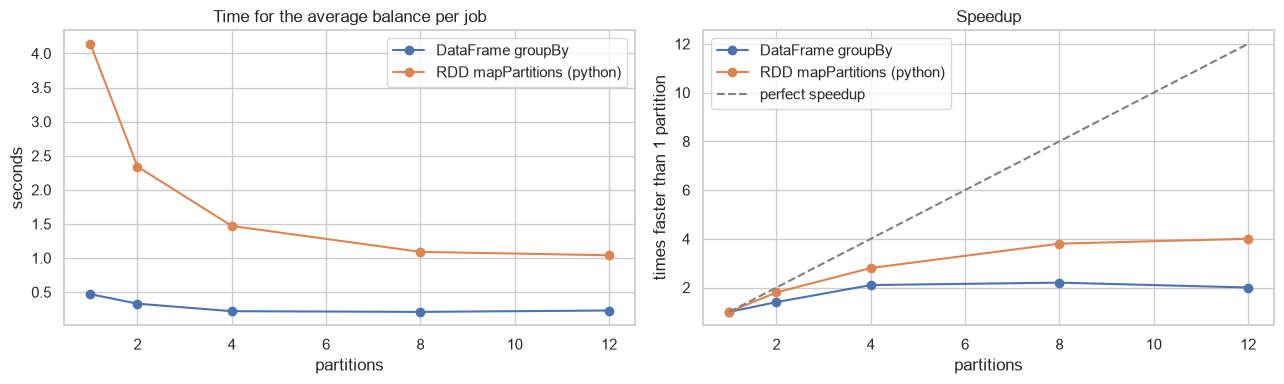

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(speed.partitions, speed.dataframe_sec, marker="o", label="DataFrame groupBy")
axes[0].plot(speed.partitions, speed.rdd_python_sec, marker="o", label="RDD mapPartitions (python)")
axes[0].set_xlabel("partitions"); axes[0].set_ylabel("seconds"); axes[0].set_title("Time for the average balance per job")
axes[0].legend()
axes[1].plot(speed.partitions, speed.dataframe_speedup, marker="o", label="DataFrame groupBy")
axes[1].plot(speed.partitions, speed.rdd_python_speedup, marker="o", label="RDD mapPartitions (python)")
axes[1].plot(speed.partitions, speed.partitions, "--", color="grey", label="perfect speedup")
axes[1].set_xlabel("partitions"); axes[1].set_ylabel("times faster than 1 partition"); axes[1].set_title("Speedup")
axes[1].legend()
plt.tight_layout(); plt.show()

**Answer:** both ways give the same averages. Retired clients have the highest average balance (2,319.19), then housemaids (2,083.80) and management (1,766.93), and blue-collar clients the lowest (1,085.16). The table of partitions 0 and 1 shows the idea of data parallelism: every partition only summarizes its own rows (for example partition 0 has 82 management clients with a total balance of 197,000), and only these small summaries are combined at the end.

**Speed:** on 4.5 million rows the version with my Python function went from 4.14 seconds on 1 partition to 1.04 seconds on 12 partitions, 4 times faster. The DataFrame version is much faster from the start (0.47 s) and gets to about 2 times faster (0.21 s on 8 partitions). It doesn't improve more because one run is so short that the fixed cost of scheduling the tasks and shuffling the partial results is a big part of it. The Python version scales better because every partition does a lot of real work.

Neither gets close to 12 times faster: the final reduce and the driver don't run in parallel, the Python workers have to send their results back to the JVM, and an Apple chip mixes fast and slower cores. Going from 8 to 12 partitions hardly helped anymore (1.09 to 1.04 s for the Python version, and the DataFrame version even got a bit slower).

### 2.2 Top 5 age groups with the highest loans

The dataset has no loan amount: `loan` (personal loan) and `housing` (housing loan) are only yes/no. So I measured
loans by **how many clients in each age group have a personal loan** and **what share of the group** that is, plus
housing loans. If a loan amount column existed, the same code would only need `F.sum("loan_amount")`.
The age groups are 5 year bands, and the work is again split by key (`repartition` on the age group) so every
partition handles whole groups.

In [13]:
band = F.floor(F.col("age") / 5) * 5
loans = (df.withColumn("age_group", F.concat(band.cast("int").cast("string"), F.lit("-"), (band + 4).cast("int").cast("string")))
           .repartition(N, "age_group")
           .groupBy("age_group")
           .agg(F.count("*").alias("clients"),
                F.sum((F.col("loan") == "yes").cast("int")).alias("personal_loans"),
                F.round(100 * F.avg((F.col("loan") == "yes").cast("int")), 1).alias("personal_loan_pct"),
                F.sum((F.col("housing") == "yes").cast("int")).alias("housing_loans"),
                F.round(100 * F.avg(((F.col("loan") == "yes") | (F.col("housing") == "yes")).cast("int")), 1).alias("any_loan_pct"))
           .cache())
print("top 5 age groups by number of personal loans")
loans.orderBy(F.desc("personal_loans")).limit(5).show()
print("top 5 age groups by share of clients with a personal loan (groups with at least 30 clients)")
loans.filter("clients >= 30").orderBy(F.desc("personal_loan_pct")).limit(5).show()

top 5 age groups by number of personal loans


+---------+-------+--------------+-----------------+-------------+------------+
|age_group|clients|personal_loans|personal_loan_pct|housing_loans|any_loan_pct|
+---------+-------+--------------+-----------------+-------------+------------+
|    30-34|    990|           171|             17.3|          636|        69.1|
|    40-44|    638|           101|             15.8|          414|        69.3|
|    35-39|    818|           100|             12.2|          514|        67.6|
|    50-54|    443|            84|             19.0|          219|        61.2|
|    45-49|    565|            83|             14.7|          312|        61.8|
+---------+-------+--------------+-----------------+-------------+------------+

top 5 age groups by share of clients with a personal loan (groups with at least 30 clients)
+---------+-------+--------------+-----------------+-------------+------------+
|age_group|clients|personal_loans|personal_loan_pct|housing_loans|any_loan_pct|
+---------+-------+--------

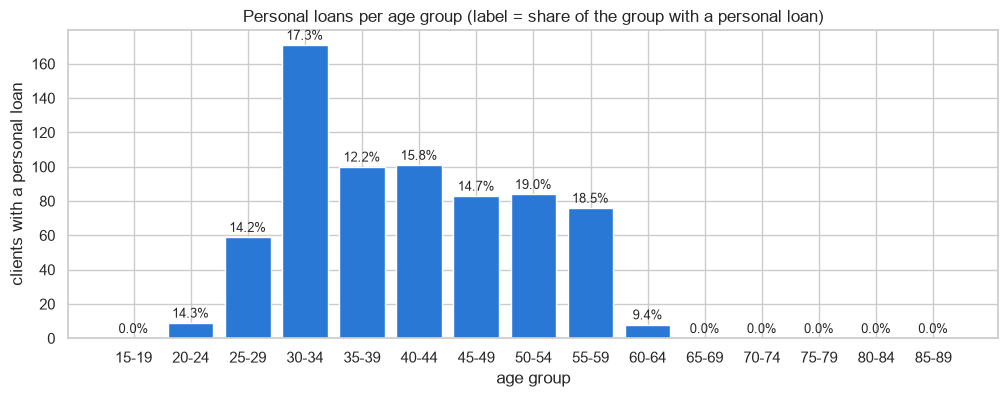

In [14]:
lp = loans.orderBy("age_group").toPandas()
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(lp.age_group, lp.personal_loans, color="#2a78d6")
ax1.set_ylabel("clients with a personal loan"); ax1.set_xlabel("age group")
for x, (n, pct) in enumerate(zip(lp.personal_loans, lp.personal_loan_pct)):
    ax1.text(x, n + 3, f"{pct}%", ha="center", fontsize=9)
ax1.set_title("Personal loans per age group (label = share of the group with a personal loan)")
plt.show()

**Answer:** ranked by the number of personal loans, the top 5 age groups are 30-34 (171 loans), 40-44 (101), 35-39 (100), 50-54 (84) and 45-49 (83). Ranked by the share of the group, the order changes: 50-54 has the highest rate (19.0% of these clients have a personal loan), then 55-59 (18.5%), 30-34 (17.3%), 40-44 (15.8%) and 45-49 (14.7%).

So the 30-34 group has the most loans mostly because it is the biggest group (990 clients), while clients in their 50s are the most likely to have one. Housing loans are much more common in the 30s and early 40s (around 69% of these clients have some loan) and drop after 55.

The work ran in parallel: the data was hash partitioned on the age group, every partition counted the loans of its own groups, and Spark combined the results.

## 3. Model Training on Partitioned Data

### 3.1 Choice of model

**Answer:** I chose **logistic regression** to predict y.

- It is a yes/no problem, and logistic regression is the standard first model for that. It also gives a probability, so the bank can rank who to call first.
- In Part 3 it was the best of the three models I tuned on this data, and in Part 4 it was fast enough to score every streamed transaction.
- Its training is naturally data parallel. Spark trains it with L-BFGS: in every iteration, each partition computes the loss and the gradient on its own rows at the same time, `treeAggregate` adds these partial gradients up, and the driver updates the weights and sends them back to the partitions. The rows never leave their partition, only a small vector of numbers per partition moves. That is why the training time goes down with more partitions, as shown below.

### 3.2 Train/test split on partitions and training

In [15]:
CAT = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
NUM = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]

# randomSplit works partition by partition: every partition splits its own rows 80/20 in parallel
train, test = df.randomSplit([0.8, 0.2], seed=42)
train = train.repartition(N).cache()
test = test.cache()
yes = lambda d: round(100 * d.filter("y = 'yes'").count() / d.count(), 1)
print(f"train {train.count()} rows ({yes(train)}% yes) | test {test.count()} rows ({yes(test)}% yes) | overall {yes(df)}% yes")

# the yes share in every training partition: the gradients of all partitions get added up,
# so it helps when every partition looks like the whole dataset
(train.withColumn("partition", spark_partition_id())
      .groupBy("partition").agg(F.count("*").alias("rows"), F.round(100 * F.avg((F.col("y") == "yes").cast("int")), 1).alias("yes_pct"))
      .orderBy("partition").toPandas().T)

train 3662 rows (11.5% yes) | test 859 rows (11.5% yes) | overall 11.5% yes


,0,1,2,3,4,5,6,7,8,9,10,11
partition,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0
rows,305.0,305.0,305.0,305.0,305.0,305.0,305.0,305.0,305.0,306.0,306.0,305.0
yes_pct,12.5,10.8,12.1,13.8,9.2,12.5,10.8,12.8,11.5,14.4,7.2,10.8


In [16]:
ys = train.filter("y = 'yes'").count() / train.count()
weighted = train.withColumn("w", F.when(F.col("y") == "yes", 0.5 / ys).otherwise(0.5 / (1 - ys)))

def make_pipeline(max_iter=50, tol=1e-6):
    return Pipeline(stages=[
        StringIndexer(inputCols=CAT, outputCols=[c + "_i" for c in CAT], handleInvalid="keep"),
        OneHotEncoder(inputCols=[c + "_i" for c in CAT], outputCols=[c + "_v" for c in CAT]),
        StringIndexer(inputCol="y", outputCol="label", stringOrderType="alphabetAsc"),
        VectorAssembler(inputCols=NUM + [c + "_v" for c in CAT], outputCol="raw"),
        StandardScaler(inputCol="raw", outputCol="features"),
        LogisticRegression(weightCol="w", maxIter=max_iter, tol=tol),
    ])

t0 = time.perf_counter()
model = make_pipeline().fit(weighted)
fit_sec = time.perf_counter() - t0
pred = model.transform(test)
auc = BinaryClassificationEvaluator(metricName="areaUnderROC").evaluate(pred)
tp = pred.filter("label = 1 AND prediction = 1").count()
print(f"trained in {fit_sec:.1f} s on {N} partitions | test AUC {auc:.3f} | "
      f"recall(yes) {tp / pred.filter('label = 1').count():.3f} | precision(yes) {tp / max(pred.filter('prediction = 1').count(), 1):.3f}")

trained in 1.7 s on 12 partitions | test AUC 0.893 | recall(yes) 0.788 | precision(yes) 0.404


**Training time against the number of partitions.** Same idea as in 2.1: the training data repeated 300 times
(about 1.1 million rows), and logistic regression run for exactly 15 iterations (`maxIter=15, tol=0`) so every setting
does the same amount of work. The model needs about 25 iterations to converge, so 15 iterations always run in full.

In [17]:
big_train = weighted.crossJoin(spark.range(300).withColumnRenamed("id", "copy")).drop("copy")
train_speed = []
for parts in [1, 2, 4, 8, N]:
    d = big_train.repartition(parts).cache(); d.count()
    t0 = time.perf_counter(); make_pipeline(max_iter=15, tol=0.0).fit(d); sec = time.perf_counter() - t0
    train_speed.append({"partitions": parts, "train_sec": round(sec, 1)})
    d.unpersist()
train_speed = pd.DataFrame(train_speed)
train_speed["speedup"] = (train_speed.train_sec.iloc[0] / train_speed.train_sec).round(1)
print(f"{big_train.count():,} training rows")
train_speed

1,098,600 training rows


,partitions,train_sec,speedup
0,1,8.0,1.0
1,2,4.5,1.8
2,4,3.1,2.6
3,8,2.4,3.3
4,12,2.3,3.5


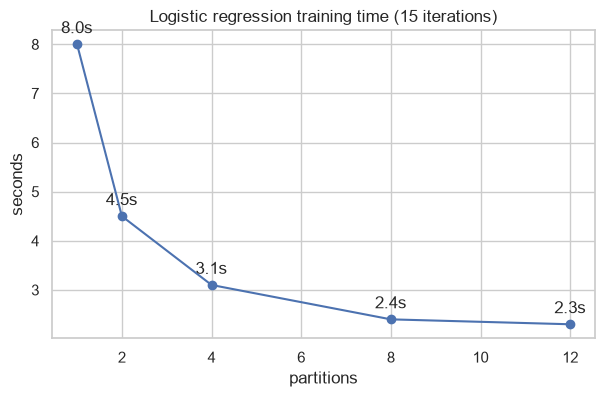

In [18]:
plt.figure(figsize=(7, 4))
plt.plot(train_speed.partitions, train_speed.train_sec, marker="o")
for p, s in zip(train_speed.partitions, train_speed.train_sec):
    plt.annotate(f"{s}s", (p, s), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xlabel("partitions"); plt.ylabel("seconds"); plt.title("Logistic regression training time (15 iterations)")
plt.show()

**Answer:** the split keeps 11.5% subscribers in both the training and the test set. Each of the 12 training partitions has 305 or 306 rows, with between 7.2% and 14.4% subscribers. The model trained in 1.7 seconds and on the test set it has an AUC of 0.893. It finds 78.8% of the subscribers, and 40.4% of the clients it flags really subscribed. This model includes duration, unlike the final model in Part 3, because the point here is the parallel training and not a realistic deployment.

On 1.1 million rows the training went from 8.0 seconds with 1 partition to 2.3 seconds with 12, 3.5 times faster, with most of the gain reached at 4 to 8 partitions.

**Challenges and how I handled them:**

- **Too few partitions:** the file is read as 1 partition, so I repartitioned to 12, one per core.
- **Too many partitions for small data:** on the real 4,521 rows the training takes about 1.7 seconds whatever I do, because the fixed cost of every iteration (scheduling tasks, adding up the gradients) is bigger than the actual work. Parallel training only pays off on bigger data, which is why I measured it on the bigger copy.
- **Partitions that don't look like the whole data:** with random partitioning one partition ended up with only 7.2% subscribers. That is why the class weights are computed on the whole training set and not per partition.
- **Reading the data again in every iteration:** logistic regression goes over the data 15 to 25 times, so the training data is cached in memory. Without the cache Spark would redo all the preparation steps in every iteration.
- **Encoding the categories the same way everywhere:** StringIndexer has to see all the data to build one mapping. Inside the Pipeline it is fitted once on the whole training set and reused for every partition and for the test set.

## 4. Resource Monitoring and Management

Two kinds of monitoring:
1. **The machine:** a small background thread that samples the CPU use of every core and the memory of the Spark JVM
   and the Python workers, every 0.2 seconds, while Spark works.
2. **Spark itself:** Spark's REST API (the data behind the Spark UI) gives the time, CPU time, shuffle and memory of
   every stage and of the executor.

The monitored run has four phases: the aggregation from 2.1 on the big data with 1 partition, the same with 12
partitions, and the model training with 1 and with 12 partitions.

In [19]:
class ResourceMonitor:
    """samples cpu and memory in a background thread"""
    def __init__(self, interval=0.2):
        self.interval, self.samples, self.marks = interval, [], []
        self._stop = threading.Event()

    def _memory(self):
        jvm = workers = 0
        for p in psutil.Process().children(recursive=True):
            try:
                rss = p.memory_info().rss
                if "java" in p.name().lower():
                    jvm += rss
                elif "python" in p.name().lower():
                    workers += rss
            except psutil.Error:
                pass
        return jvm / 2**20, workers / 2**20

    def _run(self):
        psutil.cpu_percent(percpu=True)
        t0 = self._start   # same clock as mark()
        while not self._stop.is_set():
            time.sleep(self.interval)
            per_core = psutil.cpu_percent(percpu=True)
            jvm, workers = self._memory()
            self.samples.append({"t": time.perf_counter() - t0, "cpu_pct": np.mean(per_core),
                                 "busy_cores": sum(c > 50 for c in per_core), "jvm_mb": jvm, "py_workers_mb": workers})

    def mark(self, label):
        self.marks.append((time.perf_counter() - self._start, label))

    def __enter__(self):
        self._start = time.perf_counter()
        self.thread = threading.Thread(target=self._run, daemon=True); self.thread.start()
        return self

    def __exit__(self, *exc):
        self._stop.set(); self.thread.join()


def phase_aggregate(parts):
    d = big.repartition(parts).cache(); d.count()
    d.select("job", "balance").rdd.mapPartitions(partial_sums).reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1])).collect()
    d.groupBy("job").agg(F.avg("balance"), F.expr("percentile_approx(balance, 0.5)")).collect()
    d.unpersist()

def phase_train(parts):
    d = big_train.repartition(parts).cache(); d.count()
    make_pipeline(max_iter=15, tol=0.0).fit(d)
    d.unpersist()

with ResourceMonitor() as mon:
    time.sleep(1.5); mon.mark("aggregate, 1 partition"); phase_aggregate(1)
    time.sleep(1.5); mon.mark(f"aggregate, {N} partitions"); phase_aggregate(N)
    time.sleep(1.5); mon.mark("train, 1 partition"); phase_train(1)
    time.sleep(1.5); mon.mark(f"train, {N} partitions"); phase_train(N)
    time.sleep(1.5); mon.mark("end")

res = pd.DataFrame(mon.samples)
print(f"{len(res)} samples over {res.t.max():.0f} seconds")

154 samples over 33 seconds


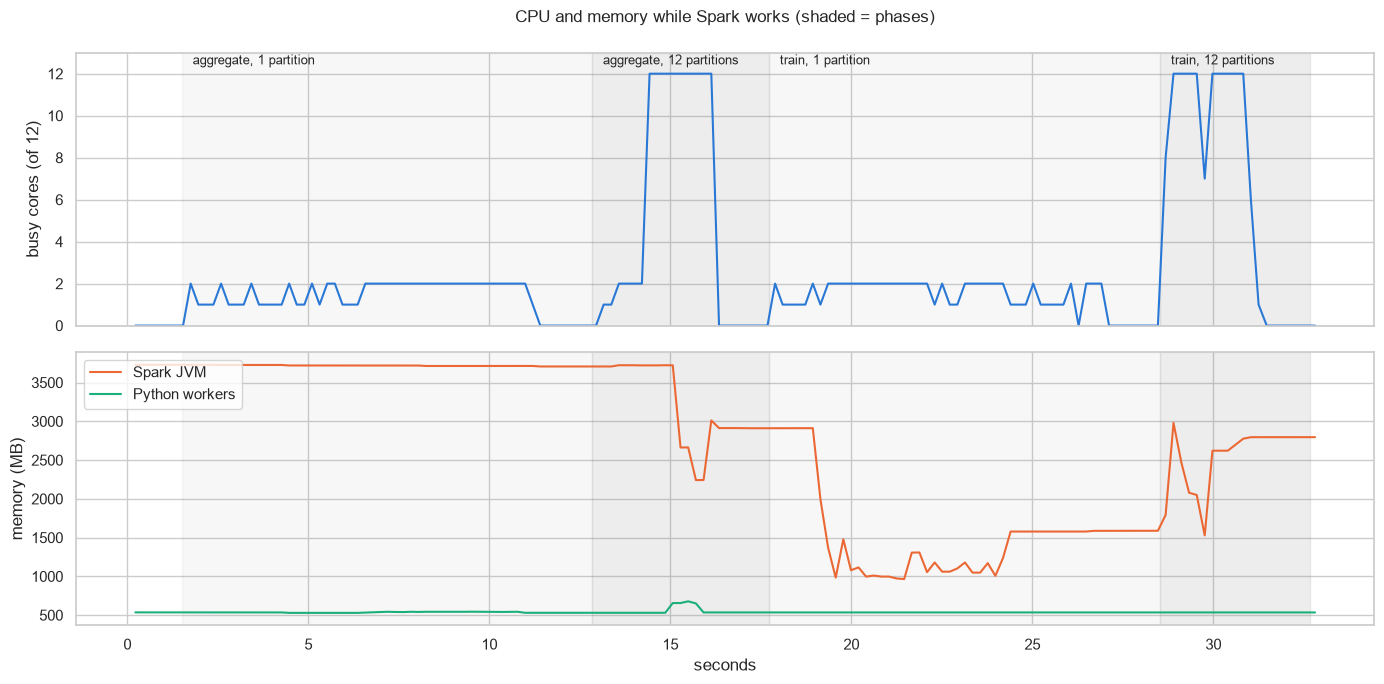

,phase,seconds,avg_busy_cores,avg_cpu_pct,max_jvm_mb,max_py_workers_mb
0,"aggregate, 1 partition",11.3,1.4,15.2,3729,543
1,"aggregate, 12 partitions",4.9,5.1,45.3,3723,677
2,"train, 1 partition",10.8,1.4,16.8,2911,534
3,"train, 12 partitions",4.1,6.8,55.0,2980,534


In [20]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(res.t, res.busy_cores, color="#2a78d6", label="cores above 50%")
axes[0].set_ylabel(f"busy cores (of {psutil.cpu_count()})"); axes[0].set_ylim(0, psutil.cpu_count() + 1)
axes[1].plot(res.t, res.jvm_mb, color="#eb6834", label="Spark JVM")
axes[1].plot(res.t, res.py_workers_mb, color="#1baf7a", label="Python workers")
axes[1].set_ylabel("memory (MB)"); axes[1].set_xlabel("seconds"); axes[1].legend(loc="upper left")
for ax in axes:
    for (t, label), (t_next, _) in zip(mon.marks[:-1], mon.marks[1:]):
        ax.axvspan(t, t_next, alpha=0.06 if "1 partition" in label else 0.14, color="grey")
for t, label in mon.marks[:-1]:
    axes[0].text(t + 0.3, psutil.cpu_count() + 0.3, label, fontsize=9, va="bottom")
axes[0].set_title("CPU and memory while Spark works (shaded = phases)", pad=22)
plt.tight_layout(); plt.show()

phases = []
for (t, label), (t_next, _) in zip(mon.marks[:-1], mon.marks[1:]):
    s = res[(res.t >= t) & (res.t < t_next)]
    phases.append({"phase": label, "seconds": round(t_next - t, 1), "avg_busy_cores": round(s.busy_cores.mean(), 1),
                   "avg_cpu_pct": round(s.cpu_pct.mean(), 1), "max_jvm_mb": int(s.jvm_mb.max()),
                   "max_py_workers_mb": int(s.py_workers_mb.max())})
pd.DataFrame(phases)

In [21]:
# spark's own numbers, from the REST API behind the Spark UI
api = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"
get = lambda path: json.load(urllib.request.urlopen(api + path))

ex = get("/executors")[0]
print(f"executor '{ex['id']}': {ex['totalCores']} cores | {ex['totalTasks']} tasks run | "
      f"task time {ex['totalDuration'] / 1000:.0f} s | GC time {ex['totalGCTime'] / 1000:.1f} s | "
      f"storage memory used {ex['memoryUsed'] / 2**20:.0f} of {ex['maxMemory'] / 2**20:.0f} MB")

stages = pd.DataFrame(get("/stages?status=complete"))
stages = stages.assign(
    run_sec=stages.executorRunTime / 1000,
    cpu_sec=stages.executorCpuTime / 1e9,
    shuffle_read_mb=stages.shuffleReadBytes / 2**20,
    shuffle_write_mb=stages.shuffleWriteBytes / 2**20,
    name=stages.name.str.slice(0, 40))
stages["cpu_share_pct"] = (100 * stages.cpu_sec / stages.run_sec.where(stages.run_sec > 0)).round(0)
(stages.sort_values("run_sec", ascending=False)
       [["stageId", "name", "numTasks", "run_sec", "cpu_sec", "cpu_share_pct", "shuffle_read_mb", "shuffle_write_mb"]]
       .head(10).round(2))

executor 'driver': 12 cores | 2684 tasks run | task time 111 s | GC time 1.5 s | storage memory used 260 of 2278 MB


,stageId,name,numTasks,run_sec,cpu_sec,cpu_share_pct,shuffle_read_mb,shuffle_write_mb
73,695,reduceByKey at /var/folders/3y/c_fv84s14,12,12.02,0.06,1.0,0.0,0.01
367,137,reduceByKey at /var/folders/3y/c_fv84s14,12,11.33,0.08,1.0,0.0,0.01
369,134,reduceByKey at /var/folders/3y/c_fv84s14,12,11.29,0.08,1.0,0.0,0.01
365,140,reduceByKey at /var/folders/3y/c_fv84s14,12,11.12,0.07,1.0,0.0,0.01
383,115,reduceByKey at /var/folders/3y/c_fv84s14,8,8.11,0.04,0.0,0.0,0.01
381,118,reduceByKey at /var/folders/3y/c_fv84s14,8,8.08,0.04,0.0,0.0,0.01
385,112,reduceByKey at /var/folders/3y/c_fv84s14,8,8.01,0.04,1.0,0.0,0.01
75,692,count at <unknown>:0,12,7.40,6.89,93.0,16.6,0.00
35,786,treeAggregate at Summarizer.scala:233,12,6.97,6.04,87.0,0.0,0.02
122,608,treeAggregate at Summarizer.scala:233,12,6.58,5.95,90.0,0.0,0.02


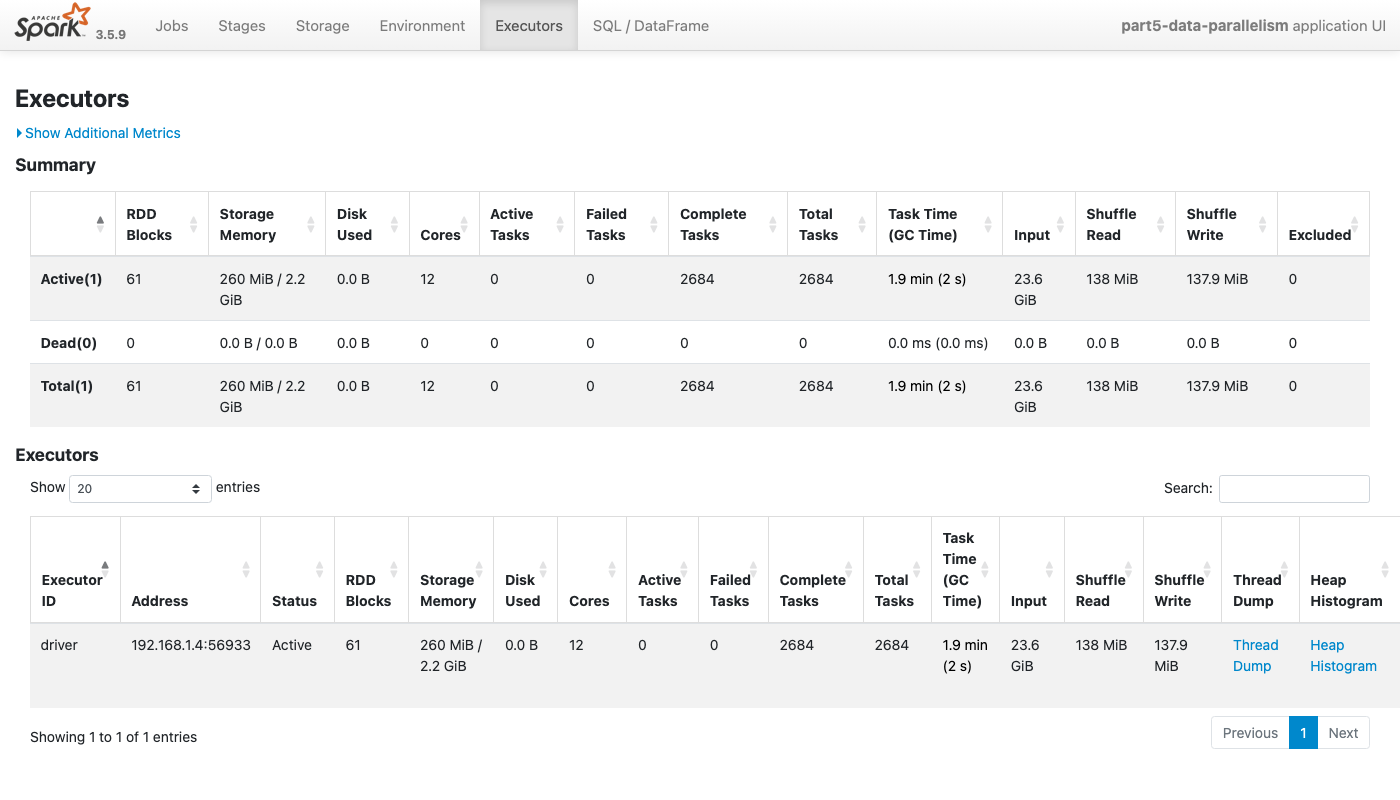

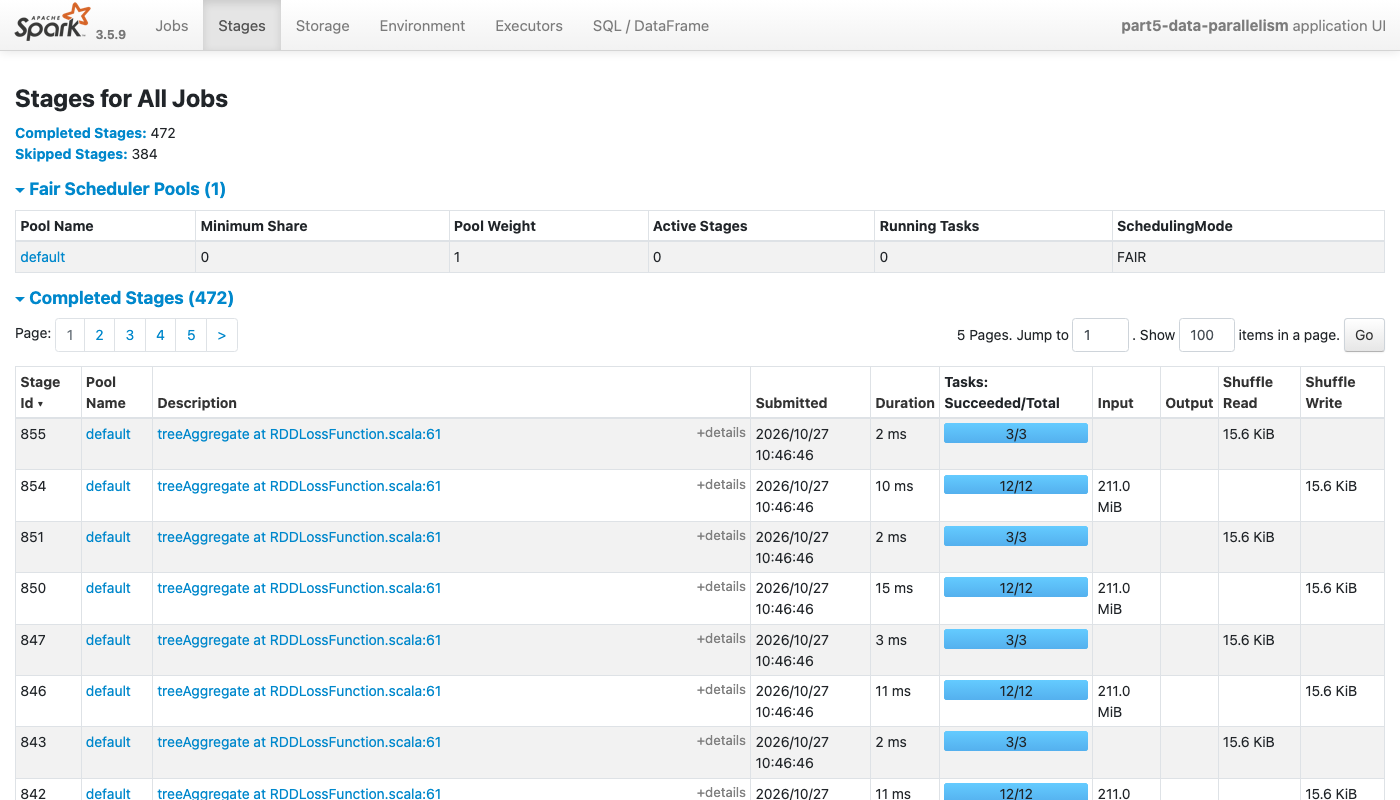

In [22]:
# a screenshot of the Spark UI itself (only when playwright is installed, so it is skipped on colab)
def spark_ui_screenshots():
    from playwright.sync_api import sync_playwright
    ui = "http://localhost:" + sc.uiWebUrl.rsplit(":", 1)[1]   # through the lan address the page's js and css didn't load
    files = []
    with sync_playwright() as p:
        browser = p.chromium.launch()
        page = browser.new_page(viewport={"width": 1400, "height": 800})
        for name, table in [("executors", "#active-executors-table tbody tr"), ("stages", "table tbody tr")]:
            page.goto(f"{ui}/{name}/"); page.wait_for_selector(table); page.wait_for_timeout(500)
            page.screenshot(path=f"spark_ui_{name}.png"); files.append(f"spark_ui_{name}.png")
        browser.close()
    return files

try:
    from IPython.display import Image, display
    # playwright's sync api can't run inside jupyter's event loop, so it runs in its own thread
    with ThreadPoolExecutor(1) as one:
        for f in one.submit(spark_ui_screenshots).result():
            display(Image(f, width=1100))
except Exception as e:
    print("no Spark UI screenshot here:", type(e).__name__, str(e)[:120])

**Answer:** what I observed:

- **CPU:** with 1 partition only about 1.4 cores were busy on average and the whole machine was at 15 to 17% CPU. With 12 partitions all 12 cores were busy during the main part of the work (the flat tops in the chart), 5 to 7 cores on average over the whole phase, and the CPU went up to 45 to 55%. Both phases finished more than twice as fast: the aggregation took 11.3 s instead of 4.9 s and the training 10.8 s instead of 4.1 s (these times include the caching and the 1.5 second pause after each phase). The cores are not busy all the time, because some parts of every job don't run in parallel (the driver, the final reduce, the shuffle between stages).
- **Memory:** the Spark JVM was at about 3.7 GB at the start, because it had grown during the earlier sections. It dropped to about 1 GB during the 1-partition training, when the cached big copy was removed and the garbage collector gave memory back to the system, and went up to about 3 GB again for the 12-partition training. The Python workers used about 540 MB, with a peak of 677 MB when 12 tasks ran my Python function at the same time. In the Executors page Spark uses 260 MB of its 2.2 GB storage memory, and garbage collection took about 1.5 seconds out of 111 seconds of task time, so memory was never a problem.
- **What Spark's own numbers show:** the stages that run my Python code (`reduceByKey`) show almost no CPU time (about 1%) even though they ran for 8 to 12 seconds. Spark only measures the CPU of the JVM, and the real work happened in the Python worker processes, which is why it is worth monitoring the machine as well. The JVM stages (the `count` of the cached data and the `treeAggregate` of the model training) spent 87 to 93% of their time on the CPU. The Stages page also shows how the training works: every iteration is a `treeAggregate` stage with 12 tasks (each partition computes the gradient of its own rows) followed by a small stage with 3 tasks that adds the 12 partial results up in groups before the driver gets them.

**How I managed the resources:** I gave the driver enough memory for caching (`spark.driver.memory` 4g), cached only data that is reused and unpersisted every test copy right after using it, kept about one partition per core for CPU heavy work, and used DataFrame functions instead of Python code where possible, because they avoid sending data between the JVM and Python.

## 5. Task Management and Scheduling

Before training, there are several independent preprocessing tasks. I wrote five of them as functions and ran them
on the big copy of the data in two ways: one after the other, and all at the same time from a thread pool. Each task
runs in its own **job group** (so it can be tracked, and cancelled if needed) and in its own **FAIR scheduler pool**
(so a long task can't block the short ones). Spark's REST API then gives the start and end of every Spark job, which
I draw as a timeline.

In [23]:
data5 = big.repartition(N).cache(); data5.count()

def numeric_summary(d):
    return d.select(NUM).summary("mean", "stddev", "min", "50%", "max").collect()

def outlier_counts(d):
    out = {}
    for c in ["balance", "duration", "campaign"]:
        q1, q3 = d.approxQuantile(c, [0.25, 0.75], 0.01)
        out[c] = d.filter((F.col(c) < q1 - 1.5 * (q3 - q1)) | (F.col(c) > q3 + 1.5 * (q3 - q1))).count()
    return out

def category_counts(d):
    return {c: d.groupBy(c).count().collect() for c in CAT}

def encode_categories(d):
    return StringIndexer(inputCols=CAT, outputCols=[c + "_i" for c in CAT], handleInvalid="keep").fit(d)

def job_profiles(d):
    return (d.groupBy("job").agg(F.avg("age"), F.avg("balance"), F.avg("duration"),
                                 F.avg((F.col("y") == "yes").cast("int"))).collect())

TASKS = {"numeric_summary": numeric_summary, "outlier_counts": outlier_counts, "category_counts": category_counts,
         "encode_categories": encode_categories, "job_profiles": job_profiles}

def run_task(run, name):
    sc.setLocalProperty("spark.scheduler.pool", name)            # FAIR pool for this thread
    sc.setJobGroup(f"{run}:{name}", f"{run} run, task {name}")   # tag every spark job of this task
    t0 = time.perf_counter(); TASKS[name](data5); sec = time.perf_counter() - t0
    sc.setLocalProperty("spark.scheduler.pool", None)
    return name, round(sec, 2)

t0 = time.perf_counter()
sequential = [run_task("sequential", n) for n in TASKS]
seq_sec = time.perf_counter() - t0

t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=len(TASKS)) as pool:
    futures = [pool.submit(run_task, "concurrent", n) for n in TASKS]
    concurrent = [f.result() for f in futures]   # .result() also re-raises an error from any task
con_sec = time.perf_counter() - t0

tasks_table = pd.DataFrame(sequential, columns=["task", "sequential_sec"]).merge(
              pd.DataFrame(concurrent, columns=["task", "concurrent_sec"]), on="task")
print(f"all five tasks: {seq_sec:.1f} s one after the other, {con_sec:.1f} s at the same time ({seq_sec / con_sec:.1f}x faster)")
tasks_table

all five tasks: 3.1 s one after the other, 1.8 s at the same time (1.7x faster)


,task,sequential_sec,concurrent_sec
0,numeric_summary,1.44,1.83
1,outlier_counts,0.80,1.13
2,category_counts,0.49,1.33
3,encode_categories,0.26,0.94
4,job_profiles,0.14,0.43


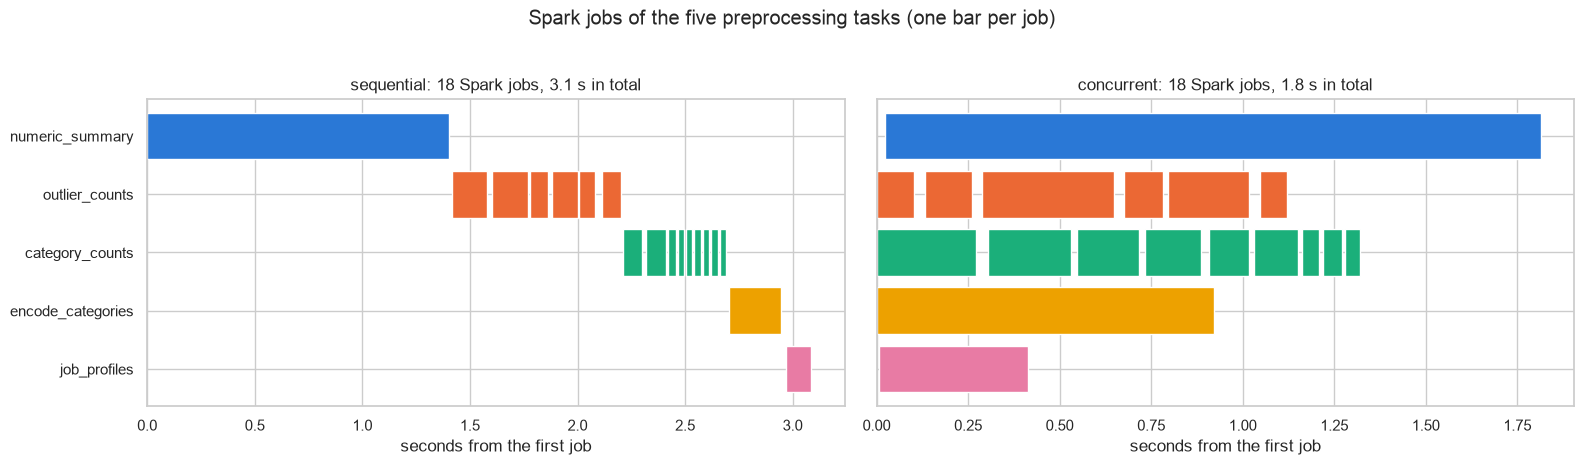

In [24]:
jobs = pd.DataFrame(get("/jobs"))
jobs = jobs[jobs.jobGroup.fillna("").str.contains(":")].copy()
for col in ["submissionTime", "completionTime"]:
    jobs[col] = pd.to_datetime(jobs[col].str.replace("GMT", ""), format="%Y-%m-%dT%H:%M:%S.%f")
jobs["run"] = jobs.jobGroup.str.split(":").str[0]
jobs["task"] = jobs.jobGroup.str.split(":").str[1]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
colors = dict(zip(TASKS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
for ax, run in zip(axes, ["sequential", "concurrent"]):
    j = jobs[jobs.run == run]
    start = j.submissionTime.min()
    for _, r in j.iterrows():
        s = (r.submissionTime - start).total_seconds(); e = (r.completionTime - start).total_seconds()
        ax.barh(r.task, max(e - s, 0.02), left=s, color=colors[r.task], edgecolor="white")
    total = (j.completionTime.max() - start).total_seconds()
    ax.set_title(f"{run}: {len(j)} Spark jobs, {total:.1f} s in total")
    ax.set_xlabel("seconds from the first job")
plt.suptitle("Spark jobs of the five preprocessing tasks (one bar per job)", y=1.03)
plt.tight_layout(); plt.show()

**Answer:** the five tasks took 3.1 seconds one after the other and 1.8 seconds at the same time, 1.7 times faster. Each task on its own gets slower when they share the cores (category_counts went from 0.49 to 1.33 s), but they overlap, so the total is shorter. The timeline shows it: in the sequential run the jobs follow each other, in the concurrent run the jobs of different tasks run side by side.

**How I managed the tasks:**

- **One thread per task**, from a ThreadPoolExecutor with 5 workers. The SparkContext is thread safe, so several threads can submit Spark jobs at the same time.
- **FAIR scheduling** (`spark.scheduler.mode = FAIR`) with one pool per task, so the cores are shared between the tasks. With Spark's default (first in, first out) the first big job would take all the cores and the short jobs would wait.
- **A job group per task** (`setJobGroup`), so every Spark job is labelled with its task in the Spark UI and in the timeline above, and a whole task could be stopped with `cancelJobGroup` if it hung.
- **The shared input is cached once**, so the five tasks don't each read and rebuild the data.
- **`future.result()`** re-raises an error from any task, so a failing task can't go unnoticed.

Running them together helps here because these tasks are small: one small job alone can't keep all 12 cores busy, so the other tasks use the idle cores.

## Conclusion

- **Partitioning decides how much can run in parallel.** The file was read as one partition. Round robin gave 12 even partitions, while hash partitioning on job was skewed (5 empty partitions) but saved a shuffle for job-level aggregations.
- **Parallel processing:** the explicit map, combine and reduce over partitions gave the same averages as Spark's groupBy. On 4.5 million rows it ran 4 times faster with 12 partitions than with 1.
- **Parallel training:** logistic regression is trained data parallel (each partition computes a gradient, treeAggregate adds them up). On 1.1 million rows it trained 3.5 times faster with 12 partitions. On the real 4,521 rows the overhead is bigger than the gain.
- **Monitoring** showed 5 to 7 busy cores on average with 12 partitions against about 1.4 with one, memory that was never close to the limit, and that Spark's own CPU numbers miss the work done in Python.
- **Scheduling:** five preprocessing tasks ran 1.7 times faster together, with FAIR pools and job groups.

The main lesson: more partitions help only up to the number of cores and only when there is enough work per partition. Even, well sized partitions, caching what is reused, and avoiding unnecessary shuffles matter more than the raw number of partitions.

In [25]:
spark.stop()